# Import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets, linear_model
from sklearn.metrics import mean_squared_error, r2_score
from numpy import log as ln

# DF

In [2]:
#First supergames.xlsx - for first super games
#second supergame.xlsx - for second super games
#MLE for K=5 for all data

In [3]:
data = pd.read_excel("MLE 2nd.xlsx")

In [4]:
data.head()

,paper,treatment:,ID,supergame,round,coop,ocoop,roundone,aftercc,aftercd,afterdc,afterdd
0,Dal Bo 2005,18,327,5,1,defect,defect,0.0,NaN,NaN,NaN,NaN
1,Dal Bo 2005,18,327,6,1,defect,coop,0.0,NaN,NaN,NaN,NaN
2,Dal Bo 2005,18,327,6,2,defect,defect,NaN,NaN,NaN,0.0,NaN
3,Dal Bo 2005,18,327,6,3,defect,defect,NaN,NaN,NaN,NaN,0.0
4,Dal Bo 2005,18,327,6,4,defect,defect,NaN,NaN,NaN,NaN,0.0


In [5]:
data.shape

(69760, 12)

# Define the Vectors

In [6]:
AC_0 , AC_CC , AC_CD , AC_DC, AC_DD = 0.9,0.9,0.9,0.9,0.9
AD_0 , AD_CC , AD_CD , AD_DC, AD_DD = 0.1,0.1,0.1,0.1,0.1
GR_0 , GR_CC , GR_CD , GR_DC, GR_DD = 0.9,0.9,0.1,0.1,0.1
AC_0 , AC_CC , AC_CD , AC_DC, AC_DD = 0.9,0.9,0.9,0.9,0.9
STFT_0 , STFT_CC , STFT_CD , STFT_DC, STFT_DD = 0.1,0.9,0.1,0.1,0.9

In [7]:
import pandas as pd
import numpy as np

# =====================================================
# RANDOM SEED
# =====================================================

np.random.seed(42)

# =====================================================
# STRATEGIES
# =====================================================


strategies = {

    "AC": {
        "0": 0.9,
        "CC": 0.9,
        "CD": 0.9,
        "DC": 0.9,
        "DD": 0.9
    },

    "AD": {
        "0": 0.1,
        "CC": 0.1,
        "CD": 0.1,
        "DC": 0.1,
        "DD": 0.1
    },

    "GR": {
        "0": 0.9,
        "CC": 0.9,
        "CD": 0.1,
        "DC": 0.1,
        "DD": 0.1
    },

    "STFT": {
        "0": 0.1,
        "CC": 0.9,
        "CD": 0.1,
        "DC": 0.9,
        "DD": 0.1
    },

    "AC2": {
        "0": 0.9,
        "CC": 0.9,
        "CD": 0.1,
        "DC": 0.9,
        "DD": 0.1
    }
}

strategy_names = list(strategies.keys())

# =====================================================
# TOURNAMENT CONFIG
# =====================================================

tournament_config = {

    4: {"n_players": 50, "supergames": [1,2,1,1,9,2,2,3,2,1,1,4,2,2,6,2,1,5,1,1,5,3,3,1]},
    5: {"n_players": 140, "supergames": [2,1,5,3,2,4,7,5,6,5,4,3,3,4,2,2,8,3,3,4,7,3,2,4,1,3,2,2,1,1,1,1,1,3,2]},
    6: {"n_players": 44, "supergames": [3,1,2,4,1,3,1,2,1,1,2,1,3,3,2,5,4,6,2,3,3,2,5,2,3,1,6,2,2,3,1,8,1,3,9,1,5,2,1,4,3,2]},
    7: {"n_players": 50, "supergames": [3,1,6,1,3,3,2,2,5,2,1,3,3,6,2,1,6,5,5,3,4,3,3,3,1,4,7,2,5,3,3,4,2,3,3]},
    8: {"n_players": 46, "supergames": [1,1,5,2,3,1,2,3,1,1,2,4,7,6,4,1,3,6,2,3,4,6,6,4,3,2,3,1,1,6,7,2,3,2,3,2,1,2,2,3,4,1,1,8]},
    9: {"n_players": 20, "supergames": [3,1,4,1,3]},
    10: {"n_players": 28, "supergames": [2,1,9,4,3,1,3,4,2,5,1]},
    11: {"n_players": 22, "supergames": [4,3,1,3,4,2,5,1,1,2,2,4,1,6]},
    12: {"n_players": 114, "supergames": [6,4,1,2,1,1,10,2,3,7,9,1,6,3,2,4,1,1,1,18,1,1,1,3,1,11]},
    13: {"n_players": 56, "supergames": [4,4,3,6,8,14,4,5,8,19,3,2,3,5,7,2,4]},
    14: {"n_players": 20, "supergames": [2,7,1,1,2,1]},
    15: {"n_players": 20, "supergames": [10,2,9,7]},
    16: {"n_players": 20, "supergames": [2,1,5,2,2,5]},
    17: {"n_players": 20, "supergames": [8,6,5]},
    18: {"n_players": 42, "supergames": [1,5,2]},
    19: {"n_players": 60, "supergames": [8,5,1,1,2]},
    20: {"n_players": 114, "supergames": [9,9,7,9,5,7,3,9,12,8,8,17,3,6,6,2,13,6]},
    21: {"n_players": 164, "supergames": [14,3,5,6,10,9,9,5,8,12,8,5,7,34,8,3,3,8,3]},
    22: {"n_players": 44, "supergames": [10,7,3,17,3,3,10,5,6,4,8,5,7,8,23,1,1,9,9]},
    23: {"n_players": 38, "supergames": [5,11,10,1,3,3,2,1,6,2,10,4,2,2,6,10,8,2,2,6,6,9,5,4,1,3,1,1,10,1,2,4,4,1,1,2,8]},
    24: {"n_players": 44, "supergames": [10,7,5,4,13,5,6,4,6,10,6,6,4,3,4,11,1,16,5,1,2,9]},
    25: {"n_players": 50, "supergames": [9,12,10,10]},
    26: {"n_players": 40, "supergames": [1,10,2,6,12]},
    27: {"n_players": 20, "supergames": [8,16,3,4]},
    28: {"n_players": 36, "supergames": [5,3,7,10,7,7,5,6,12,3,7]},
    29: {"n_players": 48, "supergames": [8,9,5,11,9]},
    30: {"n_players": 20, "supergames": [9,12]},
    31: {"n_players": 20, "supergames": [18,6,8]},
    32: {"n_players": 102, "supergames": [3,9,19,27,30,34,19,9,38]},
    33: {"n_players": 168, "supergames": [19,43,15,16,10,20,9,11,44,8,13,19,27,9,6,8,5,9]},
    34: {"n_players": 38, "supergames": [7,11,22,14,7]},
    35: {"n_players": 36, "supergames": [42,14,40]}
}

# =====================================================
# ACTION FUNCTION
# =====================================================

def sample_action(prob):
    return np.random.choice(["C","D"], p=[prob,1-prob])

# =====================================================
# SIMULATION
# =====================================================

results = []
global_player_id = 1

for tournament_id, config in tournament_config.items():

    n_players = config["n_players"]
    supergames = config["supergames"]

    players = pd.DataFrame({
        "player_id": range(global_player_id,
                           global_player_id + n_players),
        "strategy": np.random.choice(
            strategy_names,
            size=n_players,
            p=[0.1,0.28,0.21,0.19,0.22]
           
        )
    })

    global_player_id += n_players

    for sg_id, n_rounds in enumerate(supergames, start=1):

        shuffled = players.sample(frac=1).reset_index(drop=True)

        pair_id = 0

        for i in range(0, n_players, 2):

            pair_id += 1

            p1 = shuffled.iloc[i]
            p2 = shuffled.iloc[i+1]

            prev_state_p1 = None
            prev_state_p2 = None

            for round_num in range(1, n_rounds+1):

                if round_num == 1:
                    prob1 = strategies[p1["strategy"]]["0"]
                    prob2 = strategies[p2["strategy"]]["0"]
                else:
                    prob1 = strategies[p1["strategy"]][prev_state_p1]
                    prob2 = strategies[p2["strategy"]][prev_state_p2]

                a1 = sample_action(prob1)
                a2 = sample_action(prob2)

                results.append([
                    tournament_id,
                    sg_id,
                    round_num,
                    pair_id,
                    p1["player_id"],
                    p2["player_id"],
                    p1["strategy"],
                    a1,
                    a2,
                    prev_state_p1,
                    prob1
                ])

                results.append([
                    tournament_id,
                    sg_id,
                    round_num,
                    pair_id,
                    p2["player_id"],
                    p1["player_id"],
                    p2["strategy"],
                    a2,
                    a1,
                    prev_state_p2,
                    prob2
                ])

                prev_state_p1 = a1 + a2
                prev_state_p2 = a2 + a1

df = pd.DataFrame(results, columns=[
    "tournament",
    "supergame",
    "round",
    "pair_id",
    "player_id",
    "opponent_id",
    "strategy",
    "action",
    "opponent_action",
    "prev_state",
    "coop_probability"
])

print("Rows:", len(df))
print("Unique Players:", df["player_id"].nunique())
print("Min ID:", df["player_id"].min())
print("Max ID:", df["player_id"].max())

df.head()

Rows: 201442
Unique Players: 1734
Min ID: 1
Max ID: 1734


,tournament,supergame,round,pair_id,player_id,opponent_id,strategy,action,opponent_action,prev_state,coop_probability
0,4,1,1,1,27,38,AD,D,C,None,0.1
1,4,1,1,1,38,27,AC,C,D,None,0.9
2,4,1,1,2,6,2,AD,D,C,None,0.1
3,4,1,1,2,2,6,AC2,C,D,None,0.9
4,4,1,1,3,45,40,AD,D,C,None,0.1


In [8]:
df.sort_values(
    ["player_id", "tournament", "supergame", "round"]
).head(20)

,tournament,supergame,round,pair_id,player_id,opponent_id,strategy,action,opponent_action,prev_state,coop_probability
24,4,1,1,13,1,29,AD,D,D,None,0.1
111,4,2,1,16,1,19,AD,D,C,None,0.1
113,4,2,2,16,1,19,AD,D,D,DC,0.1
193,4,3,1,22,1,8,AD,D,C,None,0.1
236,4,4,1,19,1,3,AD,D,C,None,0.1
628,4,5,1,22,1,8,AD,D,C,None,0.1
630,4,5,2,22,1,8,AD,D,D,DC,0.1
632,4,5,3,22,1,8,AD,C,D,DD,0.1
634,4,5,4,22,1,8,AD,D,C,CD,0.1
636,4,5,5,22,1,8,AD,D,D,DC,0.1


In [9]:
df.shape

(201442, 11)

In [10]:
#df.to_excel("df_sim_dalbo.xlsx")

# Dalbo & F

In [15]:
df= pd.read_excel("df_sim_dalbo_str.xlsx")

In [16]:
df.head()

,ID,coop empty h,after CC,after CD,after DC,after DD,class5
0,1,0.000000,0.0625,0.000000,0.000000,0.250000,AD
1,2,0.958333,1.0000,0.111111,1.000000,0.000000,TFT
2,3,0.083333,1.0000,0.000000,0.833333,0.125000,STFT
3,4,0.083333,0.0000,0.000000,0.909091,0.050000,AD
4,5,0.125000,0.0000,0.041667,0.000000,0.041667,AD


In [17]:
df2 = df[['coop empty h','after CC','after CD','after DC','after DD']]

C:\Users\itayt\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


The optimal number of clusters is: 4


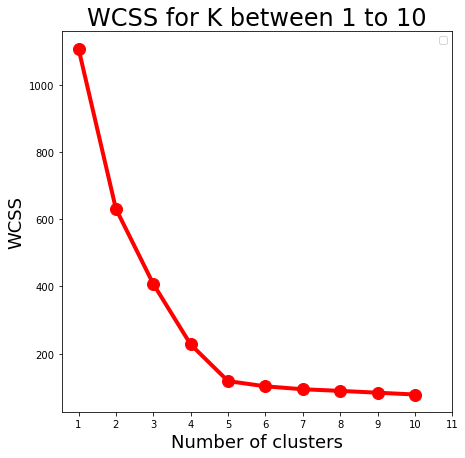

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from kneed import KneeLocator

# נתונים
x = df2.iloc[:, [0, 1, 2, 3, 4]].values

# חישוב WCSS עבור מספר קלאסטרים שונים
WCSS = []
for i in range(1, 11):
    model = KMeans(n_clusters=i, init='k-means++', max_iter=100)
    model.fit(x)
    WCSS.append(model.inertia_)

# חיפוש נקודת הברך
kneedle = KneeLocator(range(1, 11), WCSS, curve='convex', direction='decreasing')
knee_point = kneedle.elbow

# הצגת התוצאות
print(f"The optimal number of clusters is: {knee_point}")

# הצגת גרף
fig = plt.figure(figsize=(7, 7))
plt.plot(range(1, 11), WCSS, linewidth=4, markersize=12, marker='o', color='red')
plt.xticks(np.arange(1, 12))
plt.xlabel("Number of clusters", fontsize=18)
plt.ylabel("WCSS", fontsize=18)
plt.title("WCSS for K between 1 to 10", fontsize=24)

# אם תרצה להציג גם את נקודת הברך:
# plt.axvline(x=knee_point, color='blue', linestyle='--',
#             label=f'Optimal number of clusters: {knee_point}')

plt.legend()

# שמירת התמונה
plt.savefig("WCSS_DF2018.png", dpi=300, bbox_inches='tight')

plt.show()

In [70]:
model = KMeans(n_clusters = 5, init = "k-means++", max_iter = 300, n_init = 10000, random_state = 0)
y_clusters = model.fit_predict(x)
df['class5'] = y_clusters

In [71]:
df.head(5)
df.to_excel("df_sim_dalbo_str2.xlsx")

## Plot

In [20]:
df= pd.read_excel("df_sim_dalbo_str.xlsx")

In [21]:
df.head()

,ID,coop empty h,after CC,after CD,after DC,after DD,class5
0,1,0.000000,0.0625,0.000000,0.000000,0.250000,AD
1,2,0.958333,1.0000,0.111111,1.000000,0.000000,TFT
2,3,0.083333,1.0000,0.000000,0.833333,0.125000,STFT
3,4,0.083333,0.0000,0.000000,0.909091,0.050000,AD
4,5,0.125000,0.0000,0.041667,0.000000,0.041667,AD


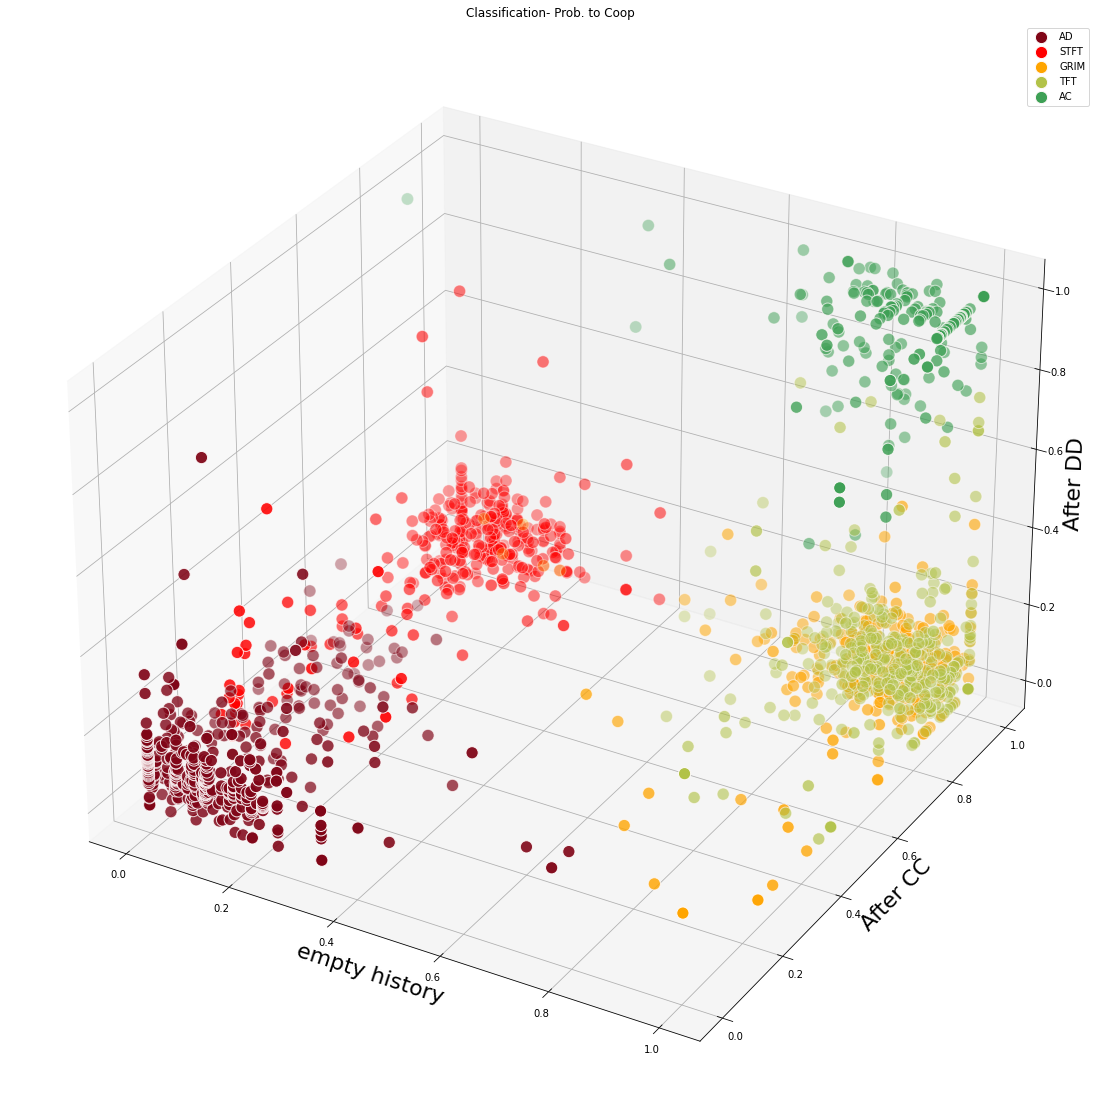

In [23]:
from matplotlib.ticker import LinearLocator, FormatStrFormatter
from mpl_toolkits.mplot3d import Axes3D


df1 = df[df['class5']=="AD"]
x1 = df1['coop empty h']
y1 = df1['after CC']
z1 = df1['after DD']

df2 = df[df['class5']=="TFT"]
x2 = df2['coop empty h']
y2 = df2['after CC']
z2 = df2['after DD']

df3 = df[df['class5']=="STFT"]
x3 = df3['coop empty h']
y3 = df3['after CC']
z3 = df3['after DD']

df4 = df[df['class5']=="AC"]
x4 = df4['coop empty h']
y4 = df4['after CC']
z4 = df4['after DD']

df0 = df[df['class5']=="GR"]
x0 = df0['coop empty h']
y0 = df0['after CC']
z0 = df0['after DD']



fig = plt.figure(figsize=(20,20))
ax = plt.axes(projection='3d')


ax.scatter3D(x1, y1, z1, edgecolor = 'snow', c = '#800517',s=150)
ax.scatter3D(x3, y3, z3, edgecolor = 'snow',c = 'r',s=150)
ax.scatter3D(x0, y0, z0, edgecolor = 'snow',c = '#FFA500',s=150)
ax.scatter3D(x2, y2, z2, edgecolor = 'snow',c = '#B2C248',s=150)
ax.scatter3D(x4, y4, z4, edgecolor = 'snow',c = '#3EA055',s =150)



ax.set_xlabel('empty history', fontsize=22, rotation=150)
ax.set_ylabel('After CC', fontsize=22, rotation=150)
ax.set_zlabel('After DD', fontsize=22, rotation=150)
plt.legend(['AD','STFT','GRIM','TFT','AC'])
plt.title("Classification- Prob. to Coop")

plt.savefig("E_CC_DD_DF2018.png", dpi=300, bbox_inches='tight')

plt.show()

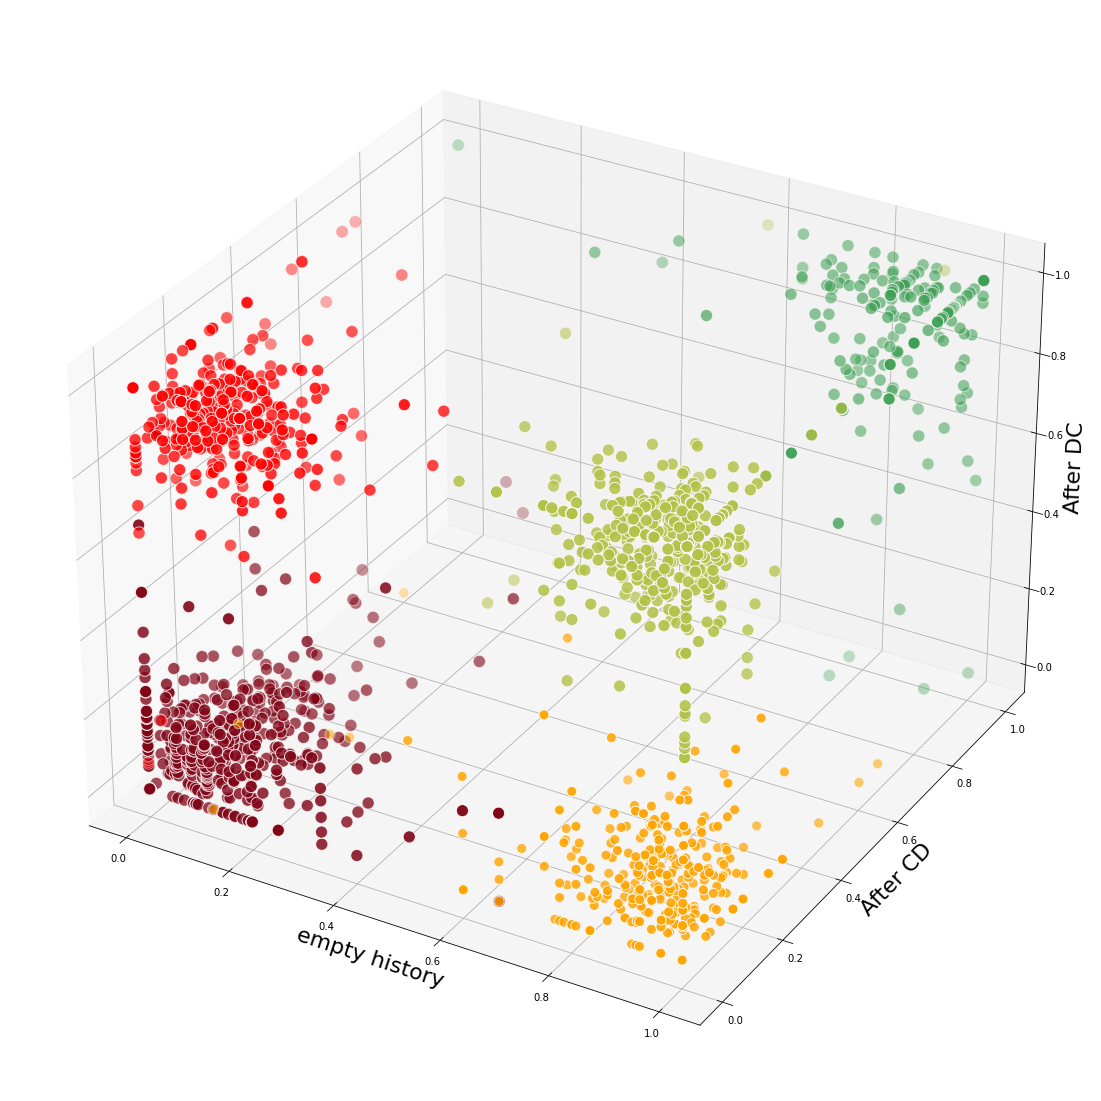

In [24]:
from matplotlib.ticker import LinearLocator, FormatStrFormatter
from mpl_toolkits.mplot3d import Axes3D

df1 = df[df['class5']=="AD"]

df2 = df[df['class5']=="TFT"]

df3 = df[df['class5']=="STFT"]

df4 = df[df['class5']=="AC"]

df0 = df[df['class5']=="GR"]

x1 = df1['coop empty h']
y1 = df1['after CD']
z1 = df1['after DC']


x2 = df2['coop empty h']
y2 = df2['after CD']
z2 = df2['after DC']

x3 = df3['coop empty h']
y3 = df3['after CD']
z3 = df3['after DC']

x4 = df4['coop empty h']
y4 = df4['after CD']
z4 = df4['after DC']

x0 = df0['coop empty h']
y0 = df0['after CD']
z0 = df0['after DC']



fig = plt.figure(figsize=(20,20))
ax = plt.axes(projection='3d')



ax.scatter3D(x1, y1, z1, edgecolor = 'snow', c = '#800517',s=150)
ax.scatter3D(x3, y3, z3, edgecolor = 'snow',c = 'r',s=150)
ax.scatter3D(x0, y0, z0, edgecolor = 'snow',c = '#FFA500',s=100)
ax.scatter3D(x2, y2, z2, edgecolor = 'snow',c = '#B2C248',s=150)
ax.scatter3D(x4, y4, z4, edgecolor = 'snow',c = '#3EA055',s =150)



ax.set_xlabel('empty history', fontsize=22, rotation=150)
ax.set_ylabel('After CD', fontsize=22, rotation=150)
ax.set_zlabel('After DC', fontsize=22, rotation=150)

plt.savefig("E_CD_DC_DF2018.png", dpi=300, bbox_inches='tight')
#plt.title("Classification- Prob. to Coop")

plt.show()

# BB2021

## Create Simulations

In [8]:
data = pd.read_excel("MLE 2nd.xlsx")

In [27]:
# =====================================================
# STRATEGIES
# =====================================================

strategies = {

    "AD": {
        "0": 0.1,
        "CC": 0.1,
        "CD": 0.1,
        "DC": 0.1,
        "DD": 0.1
    },

    "SGC": {
        "0": 0.9,
        "CC": 0.9,
        "CD": 0.3,
        "DC": 0.3,
        "DD": 0.1
    },

    "SGD": {
        "0": 0.3,
        "CC": 0.9,
        "CD": 0.3,
        "DC": 0.3,
        "DD": 0.1
    }
}

strategy_names = ["AD", "SGC", "SGD"]

strategy_probs = [0.24, 0.40, 0.36]

tournament_config = {

    4: {"n_players": 50, "supergames": [1,2,1,1,9,2,2,3,2,1,1,4,2,2,6,2,1,5,1,1,5,3,3,1]},
    5: {"n_players": 140, "supergames": [2,1,5,3,2,4,7,5,6,5,4,3,3,4,2,2,8,3,3,4,7,3,2,4,1,3,2,2,1,1,1,1,1,3,2]},
    6: {"n_players": 44, "supergames": [3,1,2,4,1,3,1,2,1,1,2,1,3,3,2,5,4,6,2,3,3,2,5,2,3,1,6,2,2,3,1,8,1,3,9,1,5,2,1,4,3,2]},
    7: {"n_players": 50, "supergames": [3,1,6,1,3,3,2,2,5,2,1,3,3,6,2,1,6,5,5,3,4,3,3,3,1,4,7,2,5,3,3,4,2,3,3]},
    8: {"n_players": 46, "supergames": [1,1,5,2,3,1,2,3,1,1,2,4,7,6,4,1,3,6,2,3,4,6,6,4,3,2,3,1,1,6,7,2,3,2,3,2,1,2,2,3,4,1,1,8]},
    9: {"n_players": 20, "supergames": [3,1,4,1,3]},
    10: {"n_players": 28, "supergames": [2,1,9,4,3,1,3,4,2,5,1]},
    11: {"n_players": 22, "supergames": [4,3,1,3,4,2,5,1,1,2,2,4,1,6]},
    12: {"n_players": 114, "supergames": [6,4,1,2,1,1,10,2,3,7,9,1,6,3,2,4,1,1,1,18,1,1,1,3,1,11]},
    13: {"n_players": 56, "supergames": [4,4,3,6,8,14,4,5,8,19,3,2,3,5,7,2,4]},
    14: {"n_players": 20, "supergames": [2,7,1,1,2,1]},
    15: {"n_players": 20, "supergames": [10,2,9,7]},
    16: {"n_players": 20, "supergames": [2,1,5,2,2,5]},
    17: {"n_players": 20, "supergames": [8,6,5]},
    18: {"n_players": 42, "supergames": [1,5,2]},
    19: {"n_players": 60, "supergames": [8,5,1,1,2]},
    20: {"n_players": 114, "supergames": [9,9,7,9,5,7,3,9,12,8,8,17,3,6,6,2,13,6]},
    21: {"n_players": 164, "supergames": [14,3,5,6,10,9,9,5,8,12,8,5,7,34,8,3,3,8,3]},
    22: {"n_players": 44, "supergames": [10,7,3,17,3,3,10,5,6,4,8,5,7,8,23,1,1,9,9]},
    23: {"n_players": 38, "supergames": [5,11,10,1,3,3,2,1,6,2,10,4,2,2,6,10,8,2,2,6,6,9,5,4,1,3,1,1,10,1,2,4,4,1,1,2,8]},
    24: {"n_players": 44, "supergames": [10,7,5,4,13,5,6,4,6,10,6,6,4,3,4,11,1,16,5,1,2,9]},
    25: {"n_players": 50, "supergames": [9,12,10,10]},
    26: {"n_players": 40, "supergames": [1,10,2,6,12]},
    27: {"n_players": 20, "supergames": [8,16,3,4]},
    28: {"n_players": 36, "supergames": [5,3,7,10,7,7,5,6,12,3,7]},
    29: {"n_players": 48, "supergames": [8,9,5,11,9]},
    30: {"n_players": 20, "supergames": [9,12]},
    31: {"n_players": 20, "supergames": [18,6,8]},
    32: {"n_players": 102, "supergames": [3,9,19,27,30,34,19,9,38]},
    33: {"n_players": 168, "supergames": [19,43,15,16,10,20,9,11,44,8,13,19,27,9,6,8,5,9]},
    34: {"n_players": 38, "supergames": [7,11,22,14,7]},
    35: {"n_players": 36, "supergames": [42,14,40]}
}

# =====================================================
# ACTION FUNCTION
# =====================================================

def sample_action(prob):
    return np.random.choice(["C","D"], p=[prob,1-prob])

# =====================================================
# SIMULATION
# =====================================================

results = []
global_player_id = 1

for tournament_id, config in tournament_config.items():

    n_players = config["n_players"]
    supergames = config["supergames"]

    players = pd.DataFrame({
        "player_id": range(global_player_id,
                           global_player_id + n_players),
        "strategy": np.random.choice(
            strategy_names,
            size=n_players,
             p=[0.24,0.40,0.36]
        )
    })

    global_player_id += n_players

    for sg_id, n_rounds in enumerate(supergames, start=1):

        shuffled = players.sample(frac=1).reset_index(drop=True)

        pair_id = 0

        for i in range(0, n_players, 2):

            pair_id += 1

            p1 = shuffled.iloc[i]
            p2 = shuffled.iloc[i+1]

            prev_state_p1 = None
            prev_state_p2 = None

            for round_num in range(1, n_rounds+1):

                if round_num == 1:
                    prob1 = strategies[p1["strategy"]]["0"]
                    prob2 = strategies[p2["strategy"]]["0"]
                else:
                    prob1 = strategies[p1["strategy"]][prev_state_p1]
                    prob2 = strategies[p2["strategy"]][prev_state_p2]

                a1 = sample_action(prob1)
                a2 = sample_action(prob2)

                results.append([
                    tournament_id,
                    sg_id,
                    round_num,
                    pair_id,
                    p1["player_id"],
                    p2["player_id"],
                    p1["strategy"],
                    a1,
                    a2,
                    prev_state_p1,
                    prob1
                ])

                results.append([
                    tournament_id,
                    sg_id,
                    round_num,
                    pair_id,
                    p2["player_id"],
                    p1["player_id"],
                    p2["strategy"],
                    a2,
                    a1,
                    prev_state_p2,
                    prob2
                ])

                prev_state_p1 = a1 + a2
                prev_state_p2 = a2 + a1

df = pd.DataFrame(results, columns=[
    "tournament",
    "supergame",
    "round",
    "pair_id",
    "player_id",
    "opponent_id",
    "strategy",
    "action",
    "opponent_action",
    "prev_state",
    "coop_probability"
])

print("Rows:", len(df))
print("Unique Players:", df["player_id"].nunique())
print("Min ID:", df["player_id"].min())
print("Max ID:", df["player_id"].max()

df.head()

SyntaxError: invalid syntax (1018300810.py, line 181)

In [10]:
df.to_excel("df_sim_BB.xlsx")

In [28]:
df= pd.read_excel("df_sim_BB2.xlsx")

In [29]:
df.head()

,ID,coop empty h,after CC,after CD,after DC,after DD
0,1,0.166667,0.000000,0.000000,0.000000,0.035714
1,2,0.250000,1.000000,0.000000,0.250000,0.136364
2,3,0.916667,0.769231,0.125000,0.500000,0.000000
3,4,0.208333,0.777778,0.342682,0.384615,0.000000
4,5,0.916667,0.900000,0.272727,0.333333,0.230769


## Clusters

C:\Users\itayt\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(


The optimal number of clusters is: 3


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


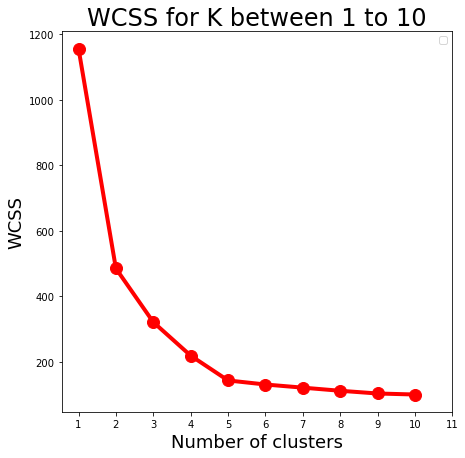

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from kneed import KneeLocator

df2 = df[['coop empty h','after CC','after CD','after DC','after DD']]
# נתונים
x = df2.iloc[:, [0, 1, 2, 3, 4]].values

# חישוב WCSS עבור מספר קלאסטרים שונים
WCSS = []
for i in range(1, 11):
    model = KMeans(n_clusters=i, init='k-means++', max_iter=100)
    model.fit(x)
    WCSS.append(model.inertia_)

# חיפוש נקודת הברך
kneedle = KneeLocator(range(1, 11), WCSS, curve='convex', direction='decreasing')
knee_point = kneedle.elbow

# הצגת התוצאות
print(f"The optimal number of clusters is: {knee_point}")

# הצגת גרף
fig = plt.figure(figsize=(7, 7))
plt.plot(range(1, 11), WCSS, linewidth=4, markersize=12, marker='o', color='red')
plt.xticks(np.arange(1, 12))                                                
plt.xlabel("Number of clusters", fontsize=18)
plt.ylabel("WCSS", fontsize=18)
plt.title("WCSS for K between 1 to 10", fontsize=24)  
#plt.axvline(x=knee_point, color='blue', linestyle='--', label=f'Optimal number of clusters: {knee_point}')

plt.savefig("WCSS_BB23.png", dpi=300, bbox_inches='tight')
plt.legend()
plt.show()


In [17]:
model = KMeans(n_clusters = 3, init = "k-means++", max_iter = 300, n_init = 10000, random_state = 0)
y_clusters = model.fit_predict(x)
df['class5'] = y_clusters

In [ ]:
df.head(5)

In [19]:
df.to_excel("df_sim_BB3.xlsx")

## Figure

In [32]:
df = pd.read_excel("df_sim_BB3.xlsx")
df.head()

,ID,after CC,after CD,after DC,after DD,coop empty h,class5,class org,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15
0,1,0.166667,0.000000,0.000000,0.000000,0.035714,2,AD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,0.250000,1.000000,0.000000,0.250000,0.136364,2,SGC,NaN,NaN,ספירה של class5,תוויות עמודה,NaN,NaN,NaN,NaN
2,3,0.916667,0.769231,0.125000,0.500000,0.000000,0,SGD,NaN,NaN,תוויות שורה,0,1,2,(ריק),סכום כולל
3,4,0.370000,0.777778,0.342682,0.384615,0.000000,2,SGC,NaN,NaN,AD,8,NaN,396,NaN,404
4,5,0.916667,0.900000,0.272727,0.333333,0.230769,0,SGD,NaN,NaN,SGC,567,32,85,NaN,684


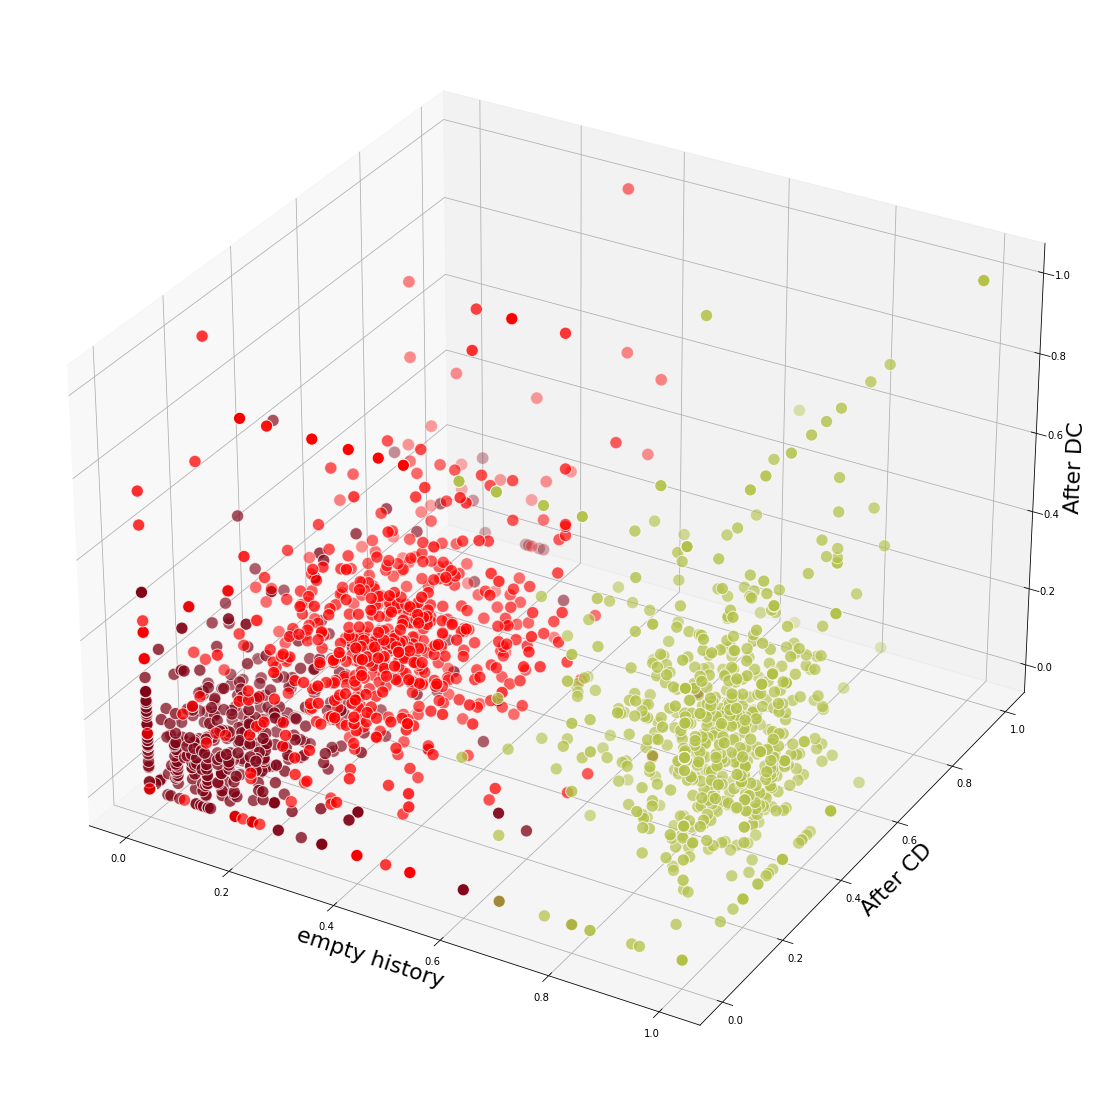

In [34]:
from matplotlib.ticker import LinearLocator, FormatStrFormatter
from mpl_toolkits.mplot3d import Axes3D

df1 = df[df['class5']==1]
x1 = df1['coop empty h']
y1 = df1['after CD']
z1 = df1['after DC']

df2 = df[df['class5']==2]
x2 = df2['coop empty h']
y2 = df2['after CD']
z2 = df2['after DC']

df3 = df[df['class5']==0]
x3 = df3['coop empty h']
y3 = df3['after CD']
z3 = df3['after DC']



fig = plt.figure(figsize=(20,20))
ax = plt.axes(projection='3d')


ax.scatter3D(x1, y1, z1, edgecolor = 'snow', c = '#B2C248',s=150)
ax.scatter3D(x3, y3, z3, edgecolor = 'snow',c = 'r',s=150)
ax.scatter3D(x2, y2, z2, edgecolor = 'snow',c = '#800517',s=150)

#ax.scatter3D(0.1, 0.1, 0.1, edgecolor = 'k',c = 'k',s=4000)
#ax.scatter3D(0.9, 0.3, 0.3, edgecolor = 'k',c = 'k',s=4000)
#ax.scatter3D(0.3, 0.3, 0.3, edgecolor = 'k',c = 'k',s=4000)


ax.set_xlabel('empty history', fontsize=22, rotation=150)
ax.set_ylabel('After CD', fontsize=22, rotation=150)
ax.set_zlabel('After DC', fontsize=22, rotation=150)

plt.savefig("E_CC_DD_BB2023.png", dpi=300, bbox_inches='tight')

#plt.title("Classification- Prob. to Coop")


plt.show()

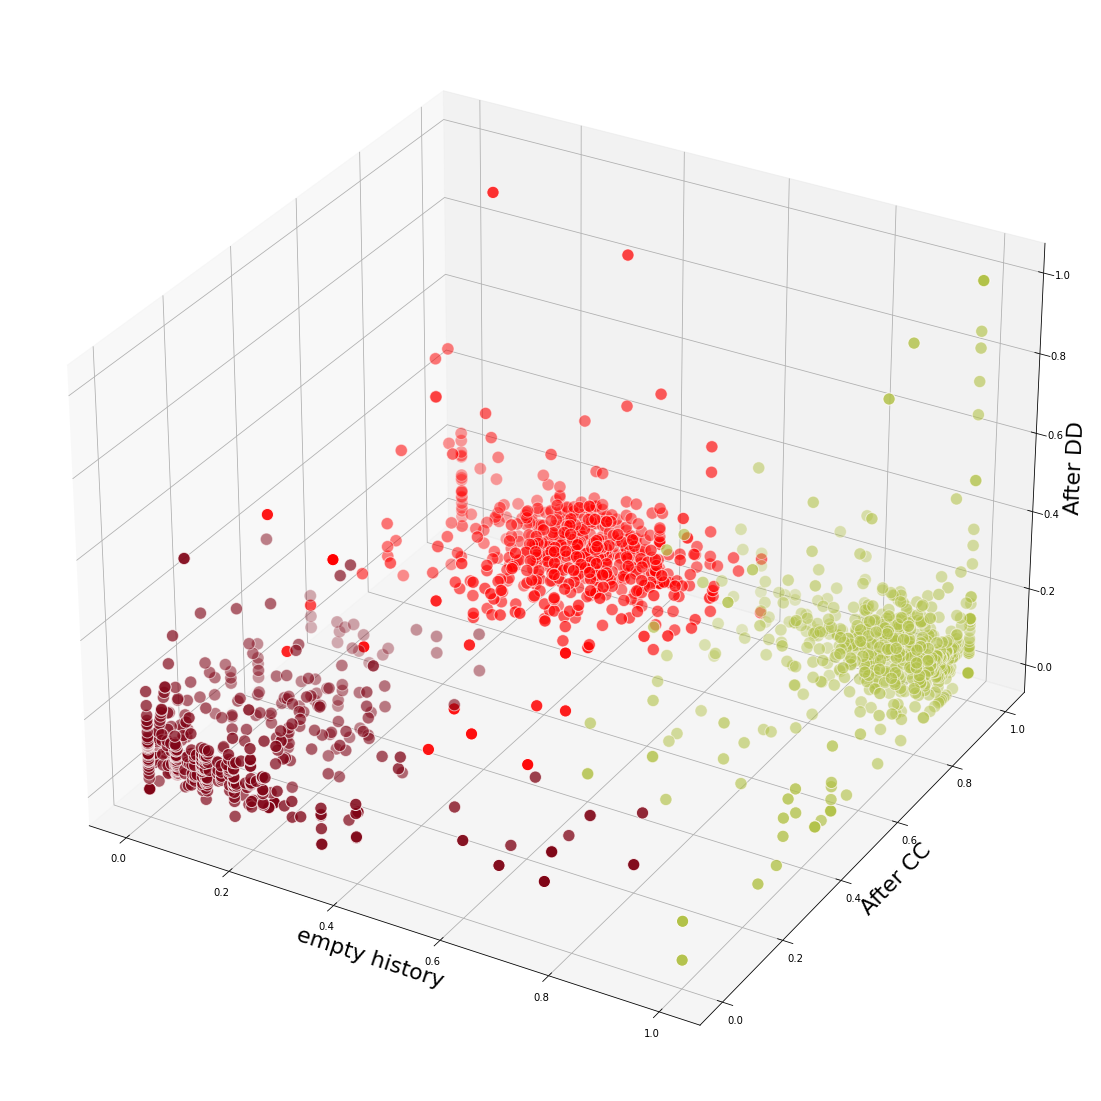

In [37]:
from matplotlib.ticker import LinearLocator, FormatStrFormatter
from mpl_toolkits.mplot3d import Axes3D

df1 = df[df['class5']==1]
x1 = df1['coop empty h']
y1 = df1['after CC']
z1 = df1['after DD']

df2 = df[df['class5']==2]
x2 = df2['coop empty h']
y2 = df2['after CC']
z2 = df2['after DD']

df3 = df[df['class5']==0]
x3 = df3['coop empty h']
y3 = df3['after CC']
z3 = df3['after DD']



fig = plt.figure(figsize=(20,20))
ax = plt.axes(projection='3d')


ax.scatter3D(x1, y1, z1, edgecolor = 'snow', c = '#B2C248',s=150)
ax.scatter3D(x3, y3, z3, edgecolor = 'snow',c = 'r',s=150)
ax.scatter3D(x2, y2, z2, edgecolor = 'snow',c = '#800517',s=150)

#ax.scatter3D(0.1, 0.1, 0.1, edgecolor = 'k',c = 'k',s=4000)
#ax.scatter3D(0.9, 0.9, 0.1, edgecolor = 'k',c = 'k',s=4000)
#ax.scatter3D(0.3, 0.9, 0.1, edgecolor = '#B2C248',c = 'k',s=4000)


ax.set_xlabel('empty history', fontsize=22, rotation=150)
ax.set_ylabel('After CC', fontsize=22, rotation=150)
ax.set_zlabel('After DD', fontsize=22, rotation=150)

plt.savefig("E_CD_DC_BB2023.png", dpi=300, bbox_inches='tight')

#plt.title("Classification- Prob. to Coop")

plt.show()

# Itay & Yuval

In [48]:
import pandas as pd
import numpy as np

# =====================================================
# RANDOM SEED
# =====================================================

np.random.seed(42)

# =====================================================
# STRATEGIES
# =====================================================


strategies = {

    "AC": {
        "0": 0.93,
        "CC": 0.99,
        "CD": 0.6,
        "DC": 0.8,
        "DD": 0.79
    },

    "AD": {
        "0": 0.04,
        "CC": 0.16,
        "CD": 0.11,
        "DC": 0.07,
        "DD": 0.01
    },

    "GR": {
        "0": 0.77,
        "CC": 0.94,
        "CD": 0.25,
        "DC": 0.13,
        "DD": 0.05
    },

    "STFT": {
        "0": 0.16,
        "CC": 0.97,
        "CD": 0.43,
        "DC": 0.73,
        "DD": 0.08
    },

    "AC2": {
        "0": 0.91,
        "CC": 0.98,
        "CD": 0.29,
        "DC": 0.81,
        "DD": 0.05
    }
}

strategy_names = list(strategies.keys())

# =====================================================
# TOURNAMENT CONFIG
# =====================================================

tournament_config = {

    4: {"n_players": 50, "supergames": [1,2,1,1,9,2,2,3,2,1,1,4,2,2,6,2,1,5,1,1,5,3,3,1]},
    5: {"n_players": 140, "supergames": [2,1,5,3,2,4,7,5,6,5,4,3,3,4,2,2,8,3,3,4,7,3,2,4,1,3,2,2,1,1,1,1,1,3,2]},
    6: {"n_players": 44, "supergames": [3,1,2,4,1,3,1,2,1,1,2,1,3,3,2,5,4,6,2,3,3,2,5,2,3,1,6,2,2,3,1,8,1,3,9,1,5,2,1,4,3,2]},
    7: {"n_players": 50, "supergames": [3,1,6,1,3,3,2,2,5,2,1,3,3,6,2,1,6,5,5,3,4,3,3,3,1,4,7,2,5,3,3,4,2,3,3]},
    8: {"n_players": 46, "supergames": [1,1,5,2,3,1,2,3,1,1,2,4,7,6,4,1,3,6,2,3,4,6,6,4,3,2,3,1,1,6,7,2,3,2,3,2,1,2,2,3,4,1,1,8]},
    9: {"n_players": 20, "supergames": [3,1,4,1,3]},
    10: {"n_players": 28, "supergames": [2,1,9,4,3,1,3,4,2,5,1]},
    11: {"n_players": 22, "supergames": [4,3,1,3,4,2,5,1,1,2,2,4,1,6]},
    12: {"n_players": 114, "supergames": [6,4,1,2,1,1,10,2,3,7,9,1,6,3,2,4,1,1,1,18,1,1,1,3,1,11]},
    13: {"n_players": 56, "supergames": [4,4,3,6,8,14,4,5,8,19,3,2,3,5,7,2,4]},
    14: {"n_players": 20, "supergames": [2,7,1,1,2,1]},
    15: {"n_players": 20, "supergames": [10,2,9,7]},
    16: {"n_players": 20, "supergames": [2,1,5,2,2,5]},
    17: {"n_players": 20, "supergames": [8,6,5]},
    18: {"n_players": 42, "supergames": [1,5,2]},
    19: {"n_players": 60, "supergames": [8,5,1,1,2]},
    20: {"n_players": 114, "supergames": [9,9,7,9,5,7,3,9,12,8,8,17,3,6,6,2,13,6]},
    21: {"n_players": 164, "supergames": [14,3,5,6,10,9,9,5,8,12,8,5,7,34,8,3,3,8,3]},
    22: {"n_players": 44, "supergames": [10,7,3,17,3,3,10,5,6,4,8,5,7,8,23,1,1,9,9]},
    23: {"n_players": 38, "supergames": [5,11,10,1,3,3,2,1,6,2,10,4,2,2,6,10,8,2,2,6,6,9,5,4,1,3,1,1,10,1,2,4,4,1,1,2,8]},
    24: {"n_players": 44, "supergames": [10,7,5,4,13,5,6,4,6,10,6,6,4,3,4,11,1,16,5,1,2,9]},
    25: {"n_players": 50, "supergames": [9,12,10,10]},
    26: {"n_players": 40, "supergames": [1,10,2,6,12]},
    27: {"n_players": 20, "supergames": [8,16,3,4]},
    28: {"n_players": 36, "supergames": [5,3,7,10,7,7,5,6,12,3,7]},
    29: {"n_players": 48, "supergames": [8,9,5,11,9]},
    30: {"n_players": 20, "supergames": [9,12]},
    31: {"n_players": 20, "supergames": [18,6,8]},
    32: {"n_players": 102, "supergames": [3,9,19,27,30,34,19,9,38]},
    33: {"n_players": 168, "supergames": [19,43,15,16,10,20,9,11,44,8,13,19,27,9,6,8,5,9]},
    34: {"n_players": 38, "supergames": [7,11,22,14,7]},
    35: {"n_players": 36, "supergames": [42,14,40]}
}

# =====================================================
# ACTION FUNCTION
# =====================================================

def sample_action(prob):
    return np.random.choice(["C","D"], p=[prob,1-prob])

# =====================================================
# SIMULATION
# =====================================================

results = []
global_player_id = 1

for tournament_id, config in tournament_config.items():

    n_players = config["n_players"]
    supergames = config["supergames"]

    players = pd.DataFrame({
        "player_id": range(global_player_id,
                           global_player_id + n_players),
        "strategy": np.random.choice(
            strategy_names,
            size=n_players,
            p=[0.15,0.32,0.17,0.14,0.22]
           
        )
    })

    global_player_id += n_players

    for sg_id, n_rounds in enumerate(supergames, start=1):

        shuffled = players.sample(frac=1).reset_index(drop=True)

        pair_id = 0

        for i in range(0, n_players, 2):

            pair_id += 1

            p1 = shuffled.iloc[i]
            p2 = shuffled.iloc[i+1]

            prev_state_p1 = None
            prev_state_p2 = None

            for round_num in range(1, n_rounds+1):

                if round_num == 1:
                    prob1 = strategies[p1["strategy"]]["0"]
                    prob2 = strategies[p2["strategy"]]["0"]
                else:
                    prob1 = strategies[p1["strategy"]][prev_state_p1]
                    prob2 = strategies[p2["strategy"]][prev_state_p2]

                a1 = sample_action(prob1)
                a2 = sample_action(prob2)

                results.append([
                    tournament_id,
                    sg_id,
                    round_num,
                    pair_id,
                    p1["player_id"],
                    p2["player_id"],
                    p1["strategy"],
                    a1,
                    a2,
                    prev_state_p1,
                    prob1
                ])

                results.append([
                    tournament_id,
                    sg_id,
                    round_num,
                    pair_id,
                    p2["player_id"],
                    p1["player_id"],
                    p2["strategy"],
                    a2,
                    a1,
                    prev_state_p2,
                    prob2
                ])

                prev_state_p1 = a1 + a2
                prev_state_p2 = a2 + a1

df = pd.DataFrame(results, columns=[
    "tournament",
    "supergame",
    "round",
    "pair_id",
    "player_id",
    "opponent_id",
    "strategy",
    "action",
    "opponent_action",
    "prev_state",
    "coop_probability"
])

print("Rows:", len(df))
print("Unique Players:", df["player_id"].nunique())
print("Min ID:", df["player_id"].min())
print("Max ID:", df["player_id"].max())

df.head()

Rows: 201442
Unique Players: 1734
Min ID: 1
Max ID: 1734


,tournament,supergame,round,pair_id,player_id,opponent_id,strategy,action,opponent_action,prev_state,coop_probability
0,4,1,1,1,27,38,AD,D,C,None,0.04
1,4,1,1,1,38,27,AC,C,D,None,0.93
2,4,1,1,2,6,2,AD,D,C,None,0.04
3,4,1,1,2,2,6,AC2,C,D,None,0.91
4,4,1,1,3,45,40,AD,D,D,None,0.04


In [49]:
df.sort_values(
    ["player_id", "tournament", "supergame", "round"]
).head(20)

,tournament,supergame,round,pair_id,player_id,opponent_id,strategy,action,opponent_action,prev_state,coop_probability
24,4,1,1,13,1,29,AD,D,D,None,0.04
111,4,2,1,16,1,19,AD,D,D,None,0.04
113,4,2,2,16,1,19,AD,D,D,DD,0.01
193,4,3,1,22,1,8,AD,D,C,None,0.04
236,4,4,1,19,1,3,AD,D,C,None,0.04
628,4,5,1,22,1,8,AD,D,C,None,0.04
630,4,5,2,22,1,8,AD,D,D,DC,0.07
632,4,5,3,22,1,8,AD,D,D,DD,0.01
634,4,5,4,22,1,8,AD,D,D,DD,0.01
636,4,5,5,22,1,8,AD,D,D,DD,0.01


In [50]:
df.shape

(201442, 11)

In [95]:
df.to_excel("df_sim_ITYUB4V.xlsx")

In [51]:
df= pd.read_excel("df_sim_ITYUB4V_STR.xlsx")

In [52]:
df2 = df[['coop empty h','after CC','after CD','after DC','after DD']]

In [53]:
df2.head(2)

,coop empty h,after CC,after CD,after DC,after DD
0,0.000000,0.011905,0.011905,0.000000,0.035714
1,0.958333,1.000000,0.333333,0.572917,0.000000


C:\Users\itayt\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(


The optimal number of clusters is: 3


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


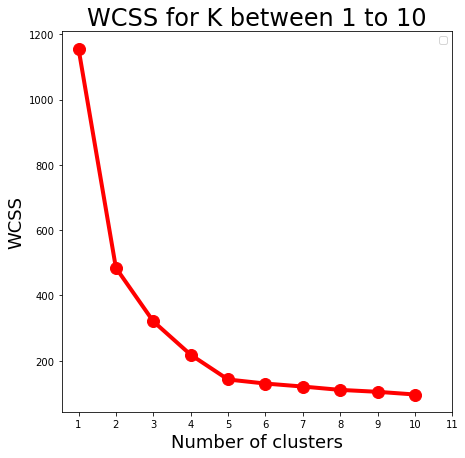

In [54]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from kneed import KneeLocator

# נתונים
x = df2.iloc[:, [0, 1, 2, 3, 4]].values

# חישוב WCSS עבור מספר קלאסטרים שונים
WCSS = []
for i in range(1, 11):
    model = KMeans(n_clusters=i, init='k-means++', max_iter=100)
    model.fit(x)
    WCSS.append(model.inertia_)

# חיפוש נקודת הברך
kneedle = KneeLocator(range(1, 11), WCSS, curve='convex', direction='decreasing')
knee_point = kneedle.elbow

# הצגת התוצאות
print(f"The optimal number of clusters is: {knee_point}")

# הצגת גרף
fig = plt.figure(figsize=(7, 7))
plt.plot(range(1, 11), WCSS, linewidth=4, markersize=12, marker='o', color='red')
plt.xticks(np.arange(1, 12))                                                
plt.xlabel("Number of clusters", fontsize=18)
plt.ylabel("WCSS", fontsize=18)
plt.title("WCSS for K between 1 to 10", fontsize=24)  
#plt.axvline(x=knee_point, color='blue', linestyle='--', label=f'Optimal number of clusters: {knee_point}')
plt.savefig("WCSS_YI26.png", dpi=300, bbox_inches='tight')
plt.legend()
plt.show()


In [55]:
model = KMeans(n_clusters = 6, init = "k-means++", max_iter = 300, n_init = 10000, random_state = 0)
y_clusters = model.fit_predict(x)
df['class6'] = y_clusters

model = KMeans(n_clusters = 2, init = "k-means++", max_iter = 300, n_init = 10000, random_state = 0)
y_clusters = model.fit_predict(x)
df['class2'] = y_clusters

model = KMeans(n_clusters = 3, init = "k-means++", max_iter = 300, n_init = 10000, random_state = 0)
y_clusters = model.fit_predict(x)
df['class3'] = y_clusters

model = KMeans(n_clusters = 4, init = "k-means++", max_iter = 300, n_init = 10000, random_state = 0)
y_clusters = model.fit_predict(x)
df['class4'] = y_clusters

model = KMeans(n_clusters = 5, init = "k-means++", max_iter = 300, n_init = 10000, random_state = 0)
y_clusters = model.fit_predict(x)
df['class5'] = y_clusters

In [56]:
df.head(5)
df.to_excel("df_sim_ITYUB4V_STR.xlsx")

In [38]:
df= pd.read_excel("df_sim_ITYUB4V_STR2.xlsx")

In [39]:
df.head(2)

,ID,coop empty h,after CC,after CD,after DC,after DD,class5,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15
0,1,0.000000,0.011905,0.011905,0.000000,0.035714,AD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AC,0.958333,1.000000,0.333333,0.572917,0.000000,TFT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


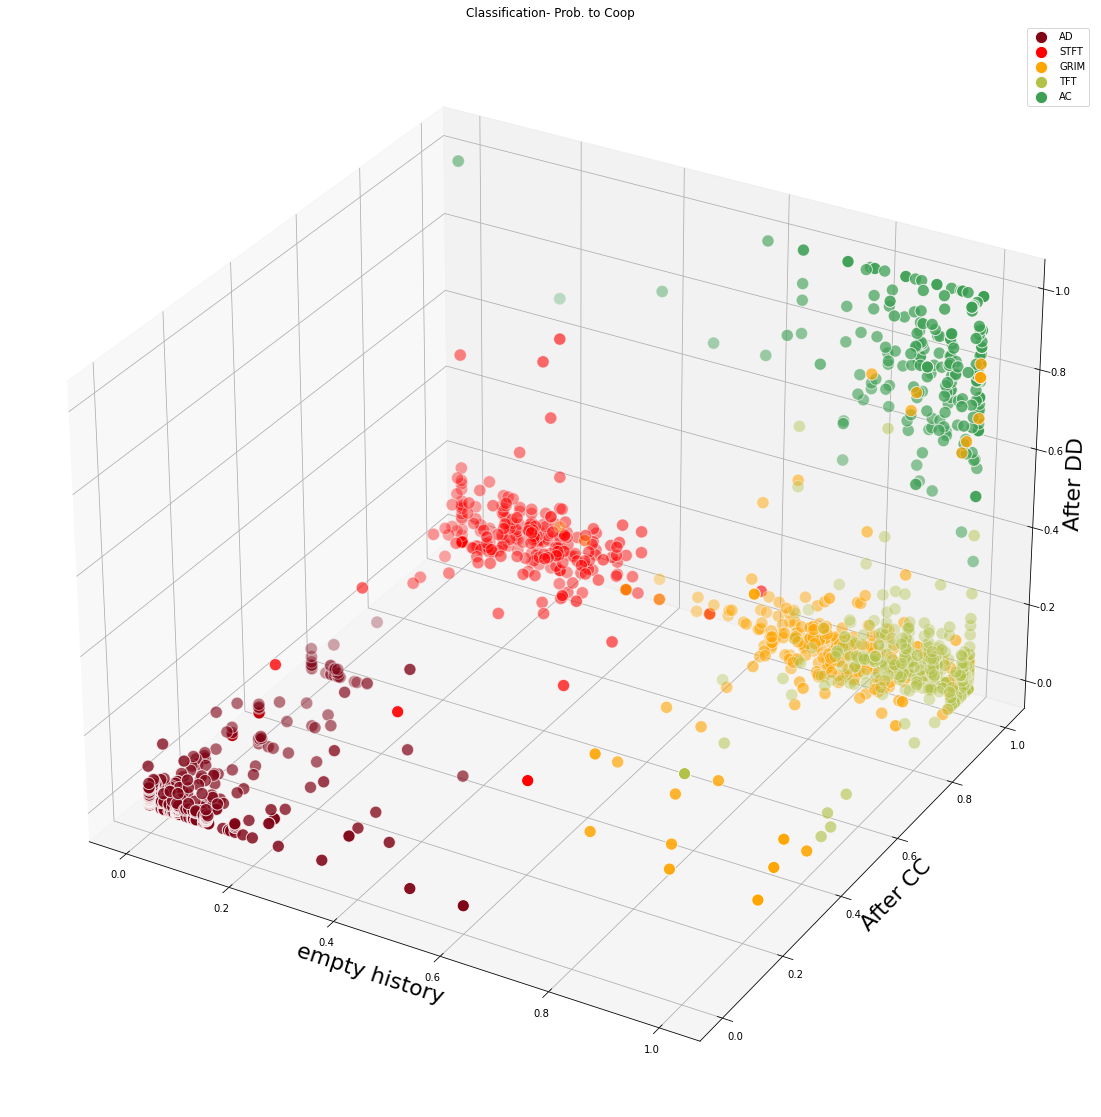

In [40]:
from matplotlib.ticker import LinearLocator, FormatStrFormatter
from mpl_toolkits.mplot3d import Axes3D


df1 = df[df['class5']=="AD"]
x1 = df1['coop empty h']
y1 = df1['after CC']
z1 = df1['after DD']

df2 = df[df['class5']=="TFT"]
x2 = df2['coop empty h']
y2 = df2['after CC']
z2 = df2['after DD']

df3 = df[df['class5']=="STFT"]
x3 = df3['coop empty h']
y3 = df3['after CC']
z3 = df3['after DD']

df4 = df[df['class5']=="AC"]
x4 = df4['coop empty h']
y4 = df4['after CC']
z4 = df4['after DD']

df0 = df[df['class5']=="GR"]
x0 = df0['coop empty h']
y0 = df0['after CC']
z0 = df0['after DD']



fig = plt.figure(figsize=(20,20))
ax = plt.axes(projection='3d')


ax.scatter3D(x1, y1, z1, edgecolor = 'snow', c = '#800517',s=150)
ax.scatter3D(x3, y3, z3, edgecolor = 'snow',c = 'r',s=150)
ax.scatter3D(x0, y0, z0, edgecolor = 'snow',c = '#FFA500',s=150)
ax.scatter3D(x2, y2, z2, edgecolor = 'snow',c = '#B2C248',s=150)
ax.scatter3D(x4, y4, z4, edgecolor = 'snow',c = '#3EA055',s =150)



ax.set_xlabel('empty history', fontsize=22, rotation=150)
ax.set_ylabel('After CC', fontsize=22, rotation=150)
ax.set_zlabel('After DD', fontsize=22, rotation=150)
plt.legend(['AD','STFT','GRIM','TFT','AC'])
plt.title("Classification- Prob. to Coop")

plt.savefig("E_CC_DD_IY26.png", dpi=300, bbox_inches='tight')

plt.show()

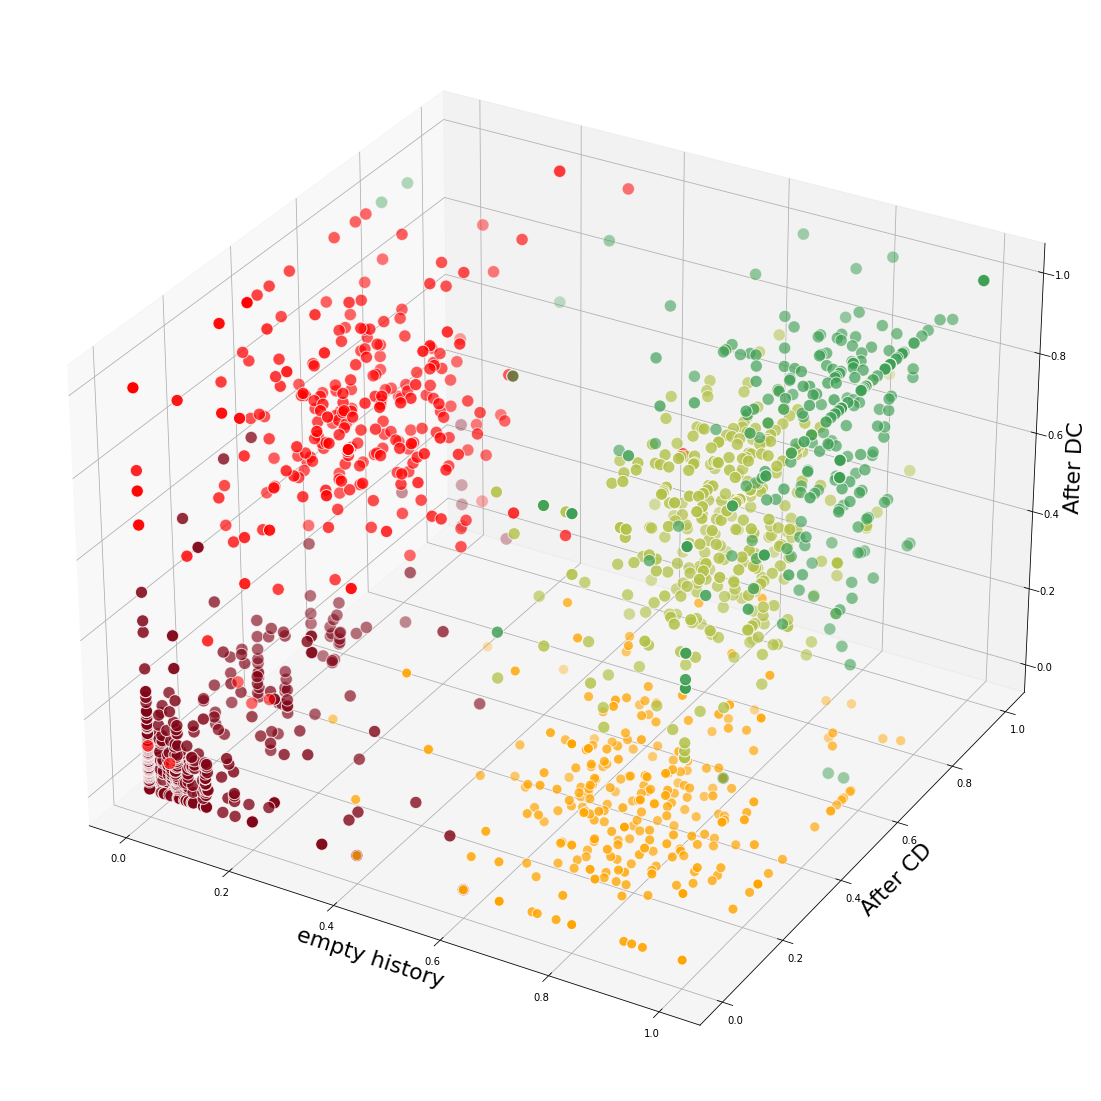

In [41]:
from matplotlib.ticker import LinearLocator, FormatStrFormatter
from mpl_toolkits.mplot3d import Axes3D

df1 = df[df['class5']=="AD"]

df2 = df[df['class5']=="TFT"]

df3 = df[df['class5']=="STFT"]

df4 = df[df['class5']=="AC"]

df0 = df[df['class5']=="GR"]

x1 = df1['coop empty h']
y1 = df1['after CD']
z1 = df1['after DC']


x2 = df2['coop empty h']
y2 = df2['after CD']
z2 = df2['after DC']

x3 = df3['coop empty h']
y3 = df3['after CD']
z3 = df3['after DC']

x4 = df4['coop empty h']
y4 = df4['after CD']
z4 = df4['after DC']

x0 = df0['coop empty h']
y0 = df0['after CD']
z0 = df0['after DC']



fig = plt.figure(figsize=(20,20))
ax = plt.axes(projection='3d')



ax.scatter3D(x1, y1, z1, edgecolor = 'snow', c = '#800517',s=150)
ax.scatter3D(x3, y3, z3, edgecolor = 'snow',c = 'r',s=150)
ax.scatter3D(x0, y0, z0, edgecolor = 'snow',c = '#FFA500',s=100)
ax.scatter3D(x2, y2, z2, edgecolor = 'snow',c = '#B2C248',s=150)
ax.scatter3D(x4, y4, z4, edgecolor = 'snow',c = '#3EA055',s =150)



ax.set_xlabel('empty history', fontsize=22, rotation=150)
ax.set_ylabel('After CD', fontsize=22, rotation=150)
ax.set_zlabel('After DC', fontsize=22, rotation=150)

plt.savefig("E_CD_DC_YI26.png", dpi=300, bbox_inches='tight')

#plt.title("Classification- Prob. to Coop")

plt.show()